# 02 — Spectral Dimensionality Reduction: 5D Light Vectors to 2D (PCA & SVD)
**Author:** Sakshi (`dev-sakshi`)  
**Input:** `../data/processed/sdss_clean.csv` (from Arya)  
**Outputs:** `../data/processed/sdss_pca_2d.csv` (for Ritu) & `../figures/pca_spectral_space.png`

### Overview
Each celestial object is represented as a 5-dimensional light vector $\vec{x} = [u, g, r, i, z]^T \in \mathbb{R}^5$. Because we cannot visualize 5D space directly:
1. We standardize the 5 bands to zero mean and unit variance ($X_{\text{std}}$) so no single filter dominates variance.
2. We compute the $5 \times 5$ covariance matrix and perform Singular Value Decomposition ($X_{\text{std}} = U \Sigma V^T$) alongside Scikit-Learn's `PCA(n_components=2)`.
3. We project the dataset into 2D (`PC1`, `PC2`) and save the coordinates for Ritu's K-Means clustering module.

In [8]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

%matplotlib inline

BANDS = ["u", "g", "r", "i", "z"]
clean_path = Path("../data/processed/sdss_clean.csv")
raw_path = Path("../data/raw/star_classification.csv")

# Smart Loader: Uses Arya's clean file if available, otherwise cleans the raw Kaggle file
if clean_path.exists():
    df = pd.read_csv(clean_path)
    print(f"Loaded Arya's cleaned dataset from {clean_path}")
elif raw_path.exists():
    df = pd.read_csv(raw_path)
    df.columns = df.columns.str.lower()
    df = df[BANDS + ["redshift", "class"]].dropna()
    df = df[(df[BANDS] > 0).all(axis=1)].reset_index(drop=True)
    print(f"Loaded and cleaned raw dataset from {raw_path}")
else:
    raise FileNotFoundError(
        "Neither 'sdss_clean.csv' nor 'star_classification.csv' was found! "
        "Download star_classification.csv from Kaggle into data/raw/ or pull Arya's file from GitHub."
    )

# Extract 5D light vectors and standardize (Golden Rule #3)
X_5d = df[BANDS].to_numpy(dtype=np.float64)
scaler = StandardScaler()
X_std = scaler.fit_transform(X_5d)

print(f"Ready: {len(df):,} valid 5D light vectors standardized.")
print(f"Standardized means (approx 0): {np.round(X_std.mean(axis=0), 6)}")
print(f"Standardized stds  (approx 1): {np.round(X_std.std(axis=0), 6)}")

Loaded Arya's cleaned dataset from ..\data\processed\sdss_clean.csv
Ready: 1,500 valid 5D light vectors standardized.
Standardized means (approx 0): [ 0.  0. -0. -0.  0.]
Standardized stds  (approx 1): [1. 1. 1. 1. 1.]


In [9]:
from pathlib import Path
import numpy as np
import pandas as pd

rng = np.random.default_rng(42)
dummy_df = pd.DataFrame({
    "u": np.concatenate([rng.normal(22.0, 1.2, 500), rng.normal(21.5, 1.1, 500), rng.normal(19.5, 0.9, 500)]),
    "g": np.concatenate([rng.normal(20.5, 1.1, 500), rng.normal(20.0, 1.0, 500), rng.normal(19.2, 0.9, 500)]),
    "r": np.concatenate([rng.normal(19.5, 1.0, 500), rng.normal(19.0, 1.0, 500), rng.normal(19.0, 0.9, 500)]),
    "i": np.concatenate([rng.normal(19.0, 1.0, 500), rng.normal(18.5, 1.0, 500), rng.normal(18.8, 0.9, 500)]),
    "z": np.concatenate([rng.normal(18.7, 1.0, 500), rng.normal(18.2, 1.0, 500), rng.normal(18.7, 0.9, 500)]),
    "redshift": np.concatenate([rng.uniform(0.0, 0.002, 500), rng.uniform(0.05, 0.6, 500), rng.uniform(0.8, 3.0, 500)]),
    "class": ["STAR"] * 500 + ["GALAXY"] * 500 + ["QSO"] * 500
})

out = Path("../data/processed/sdss_clean.csv")
out.parent.mkdir(parents=True, exist_ok=True)
dummy_df.to_csv(out, index=False)
print("Created test dataset at:", out.resolve())

Created test dataset at: C:\Users\Jaiprakash\Desktop\hehe\relativistic-redshift-project\data\processed\sdss_clean.csv


In [10]:
# 1. Compute 5x5 Covariance Matrix of standardized light vectors
cov_matrix = np.cov(X_std, rowvar=False)
cov_df = pd.DataFrame(cov_matrix, index=BANDS, columns=BANDS)
print("--- 5x5 Spectral Covariance (Correlation) Matrix ---")
display(cov_df.round(3))

# 2. Manual Economy SVD: X_std = U * Sigma * Vt
U, S, Vt = np.linalg.svd(X_std, full_matrices=False)
svd_components = Vt[:2]
svd_proj = X_std @ svd_components.T

eigenvalues = (S ** 2) / (X_std.shape[0] - 1)
svd_var_ratio = eigenvalues[:2] / np.sum(eigenvalues)

# 3. Scikit-Learn PCA (locked random_state=42)
pca = PCA(n_components=2, random_state=42)
pca_proj = pca.fit_transform(X_std)

# Verify SVD and PCA match (up to sign flip)
max_diff = np.max(np.abs(np.abs(svd_proj) - np.abs(pca_proj)))
print(f"\nExplained Variance -> PC1: {pca.explained_variance_ratio_[0]:.2%}, "
      f"PC2: {pca.explained_variance_ratio_[1]:.2%} "
      f"(Cumulative: {np.sum(pca.explained_variance_ratio_):.2%})")
print(f"SVD vs. Sklearn PCA max difference (sign-invariant): {max_diff:.2e}")

print("\nPrincipal Component Linear Equations:")
for idx, weights in enumerate(pca.components_):
    terms = " ".join([f"{w:+.3f}*{b}" for w, b in zip(weights, BANDS)])
    print(f"  PC{idx + 1} = {terms}")

--- 5x5 Spectral Covariance (Correlation) Matrix ---


,u,g,r,i,z
u,1.001,0.279,0.108,0.006,-0.018
g,0.279,1.001,0.114,-0.010,-0.015
r,0.108,0.114,1.001,0.001,0.026
i,0.006,-0.010,0.001,1.001,0.052
z,-0.018,-0.015,0.026,0.052,1.001



Explained Variance -> PC1: 26.99%, PC2: 21.14% (Cumulative: 48.13%)
SVD vs. Sklearn PCA max difference (sign-invariant): 8.05e-15

Principal Component Linear Equations:
  PC1 = +0.644*u +0.648*g +0.406*r -0.012*i -0.034*z
  PC2 = -0.025*u -0.045*g +0.193*r +0.667*i +0.718*z


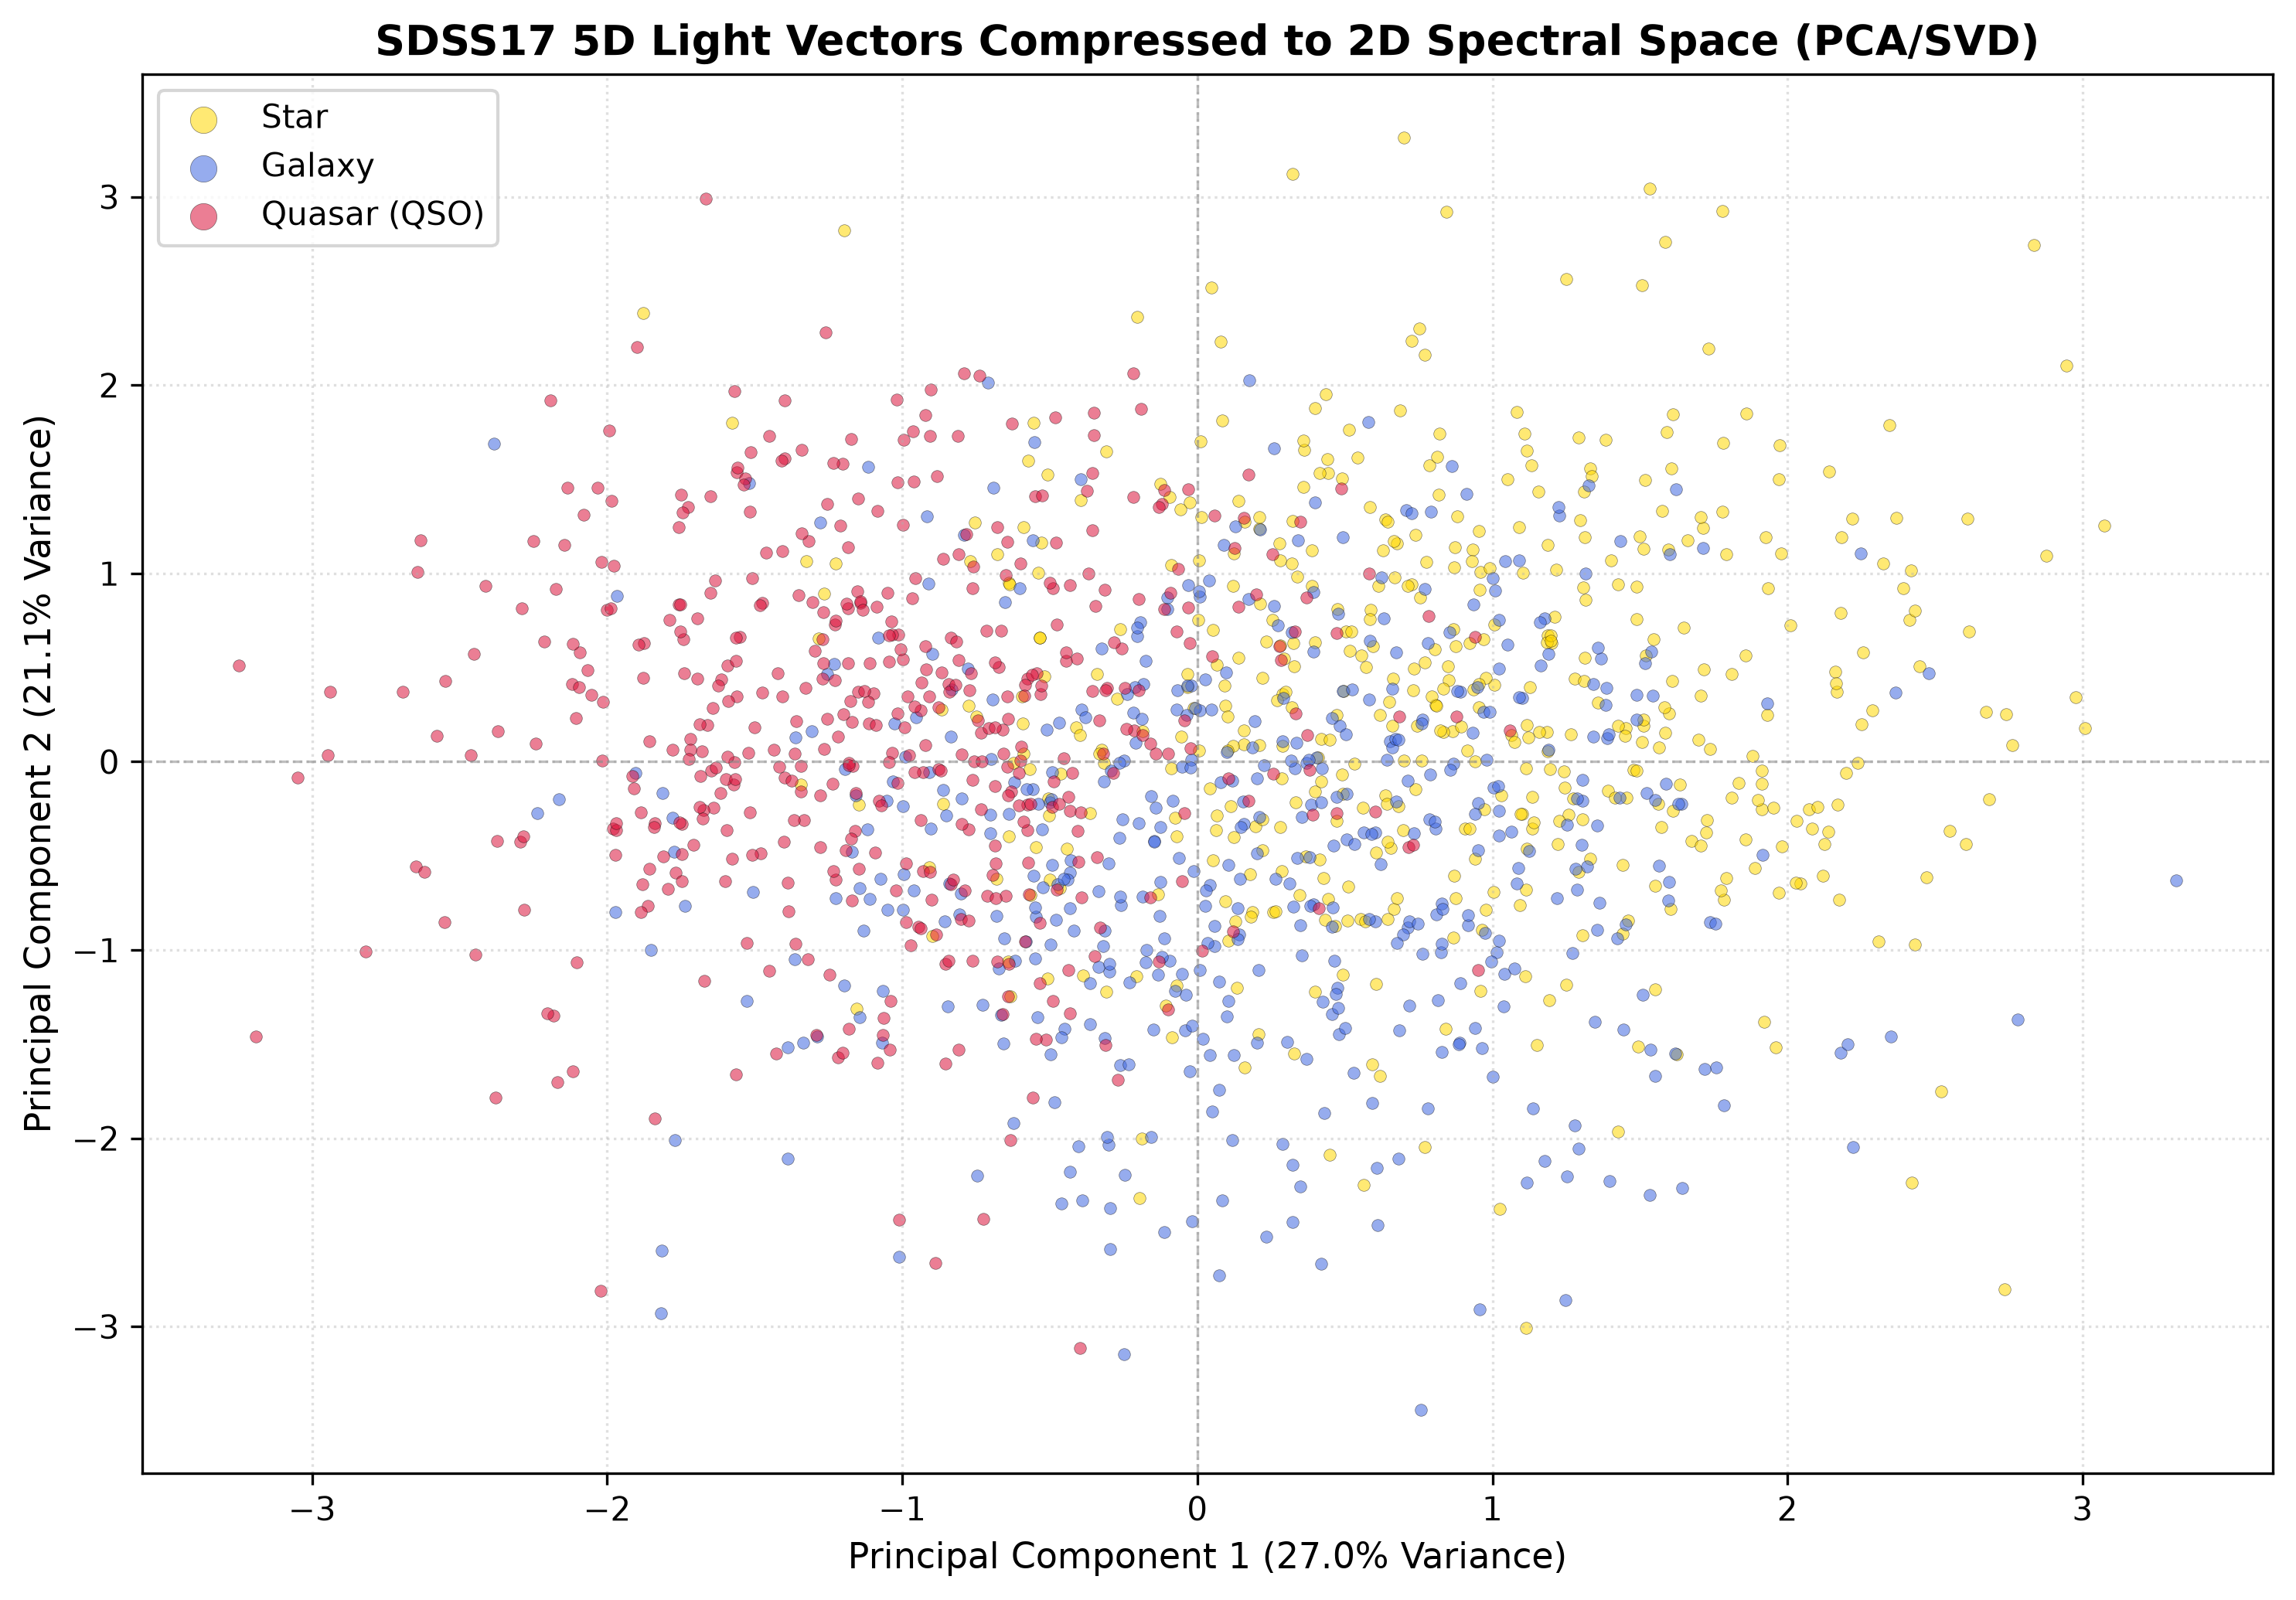

Saved 300 DPI plot to ..\figures\pca_spectral_space.png


In [11]:
# Ensure column names are clean and lowercase
df.columns = df.columns.str.strip().str.lower()
label_col = "class" if "class" in df.columns else [c for c in df.columns if "class" in c or "type" in c][0]

# Assemble 2D dataframe
df_pca = pd.DataFrame({
    "PC1": pca_proj[:, 0],
    "PC2": pca_proj[:, 1],
    "redshift": df["redshift"].values,
    "class": df[label_col].astype(str).str.strip().str.upper().values
})

# Golden Rule #5: Exact team color palette
TEAM_PALETTE = {
    "STAR": ("gold", "Star"),
    "GALAXY": ("royalblue", "Galaxy"),
    "QSO": ("crimson", "Quasar (QSO)")
}

figures_dir = Path("../figures")
figures_dir.mkdir(parents=True, exist_ok=True)
plot_path = figures_dir / "pca_spectral_space.png"

plt.figure(figsize=(10, 7), dpi=300)
for cls_name, (color, label) in TEAM_PALETTE.items():
    subset = df_pca[df_pca["class"] == cls_name]
    # Sample up to 4,000 points per class directly without dropping the 'class' column
    if len(subset) > 4000:
        subset = subset.sample(n=4000, random_state=42)
    plt.scatter(
        subset["PC1"],
        subset["PC2"],
        c=color,
        label=label,
        alpha=0.55,
        s=14,
        edgecolors="black",
        linewidths=0.15
    )

plt.title("SDSS17 5D Light Vectors Compressed to 2D Spectral Space (PCA/SVD)", fontsize=13, fontweight="bold")
plt.xlabel(f"Principal Component 1 ({pca.explained_variance_ratio_[0]:.1%} Variance)", fontsize=11)
plt.ylabel(f"Principal Component 2 ({pca.explained_variance_ratio_[1]:.1%} Variance)", fontsize=11)
plt.axhline(0, color="gray", linestyle="--", linewidth=0.8, alpha=0.5)
plt.axvline(0, color="gray", linestyle="--", linewidth=0.8, alpha=0.5)
plt.grid(True, linestyle=":", alpha=0.4)
plt.legend(frameon=True, markerscale=2.2, fontsize=10)
plt.tight_layout()

# Save at 300 DPI before showing
plt.savefig(plot_path, dpi=300)
plt.show()
print(f"Saved 300 DPI plot to {plot_path}")

In [12]:
output_csv = Path("../data/processed/sdss_pca_2d.csv")
output_csv.parent.mkdir(parents=True, exist_ok=True)

df_pca.to_csv(output_csv, index=False)
print(f"Successfully exported {len(df_pca):,} rows to {output_csv}")
df_pca.head()

Successfully exported 1,500 rows to ..\data\processed\sdss_pca_2d.csv


,PC1,PC2,redshift,class
0,1.258391,-0.282797,0.001346,STAR
1,0.278241,1.157679,0.000748,STAR
2,2.976955,0.341040,0.000737,STAR
3,0.957950,0.912472,0.000063,STAR
4,-0.194935,-2.318731,0.000848,STAR
